# Run the matmul Roofline benchmark on Colab

1. `Runtime` > `Change runtime type` > **T4 GPU**.
2. Run the cells in order. Compiling the extension takes about a minute.
3. Download the `results/` folder and commit it to the repository.

In [1]:
!git clone https://github.com/djameledinekh-lab/cuda-matmul-roofline.git
%cd cuda-matmul-roofline
!pip -q install -r requirements.txt
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv

Cloning into 'cuda-matmul-roofline'...
remote: Enumerating objects: 14, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 14 (delta 0), reused 14 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (14/14), 8.78 KiB | 8.78 MiB/s, done.
/content/cuda-matmul-roofline
name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07


In [7]:
!python bench.py --coarse 2

GPU: Tesla T4 | peak 8.1 TFLOPS FP32 | 320.0 GB/s | ridge 25.3 FLOP/B
Compiling kernels (COARSE=2), about a minute the first time...
Correctness:
  naive      max |error| vs torch.matmul = 6.10e-05  OK
  tiled      max |error| vs torch.matmul = 6.10e-05  OK
  coarsened  max |error| vs torch.matmul = 6.10e-05  OK
  N=256 done
  N=512 done
  N=1024 done
  N=2048 done
  N=4096 done
   kernel    N  time_ms  tflops      ai  pct_of_peak  pct_of_cublas
    naive  256    0.128   0.262   0.250        3.240         32.109
    tiled  256    0.086   0.389   8.000        4.800         47.578
coarsened  256    0.052   0.640  16.000        7.898         78.275
   cuBLAS  256    0.041   0.817  42.667       10.090        100.000
    naive  512    0.921   0.292   0.250        3.600         12.045
    tiled  512    0.590   0.455   8.000        5.618         18.797
coarsened  512    0.339   0.793  16.000        9.787         32.746
   cuBLAS  512    0.111   2.421  85.333       29.886        100.000
    na

In [8]:
!python bench.py --coarse 4 --sizes 1024 2048 4096

GPU: Tesla T4 | peak 8.1 TFLOPS FP32 | 320.0 GB/s | ridge 25.3 FLOP/B
Compiling kernels (COARSE=4), about a minute the first time...
Correctness:
  naive      max |error| vs torch.matmul = 5.91e-05  OK
  tiled      max |error| vs torch.matmul = 5.91e-05  OK
  coarsened  max |error| vs torch.matmul = 5.91e-05  OK
  N=1024 done
  N=2048 done
  N=4096 done
   kernel    N  time_ms  tflops      ai  pct_of_peak  pct_of_cublas
    naive 1024    7.057   0.304   0.250        3.757          5.327
    tiled 1024    2.691   0.798   8.000        9.851         13.966
coarsened 1024    0.846   2.539  16.000       31.345         44.440
   cuBLAS 1024    0.376   5.713 170.667       70.535        100.000
    naive 2048   41.195   0.417   0.250        5.149         10.772
    tiled 2048   19.420   0.885   8.000       10.921         22.849
coarsened 2048    7.867   2.184  16.000       26.960         56.405
   cuBLAS 2048    4.437   3.872 341.333       47.797        100.000
    tiled 4096  155.878   0.882 

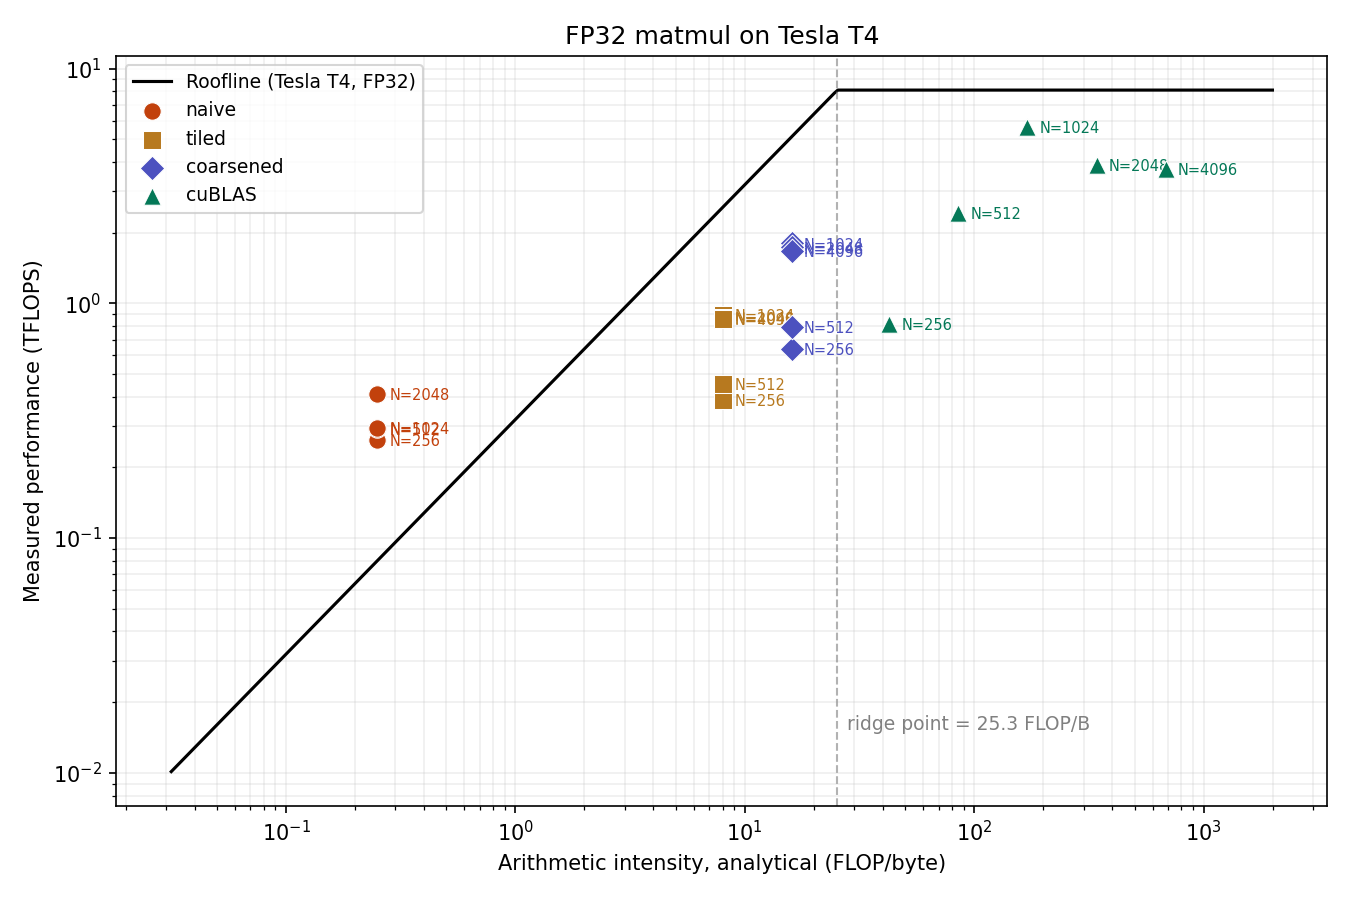

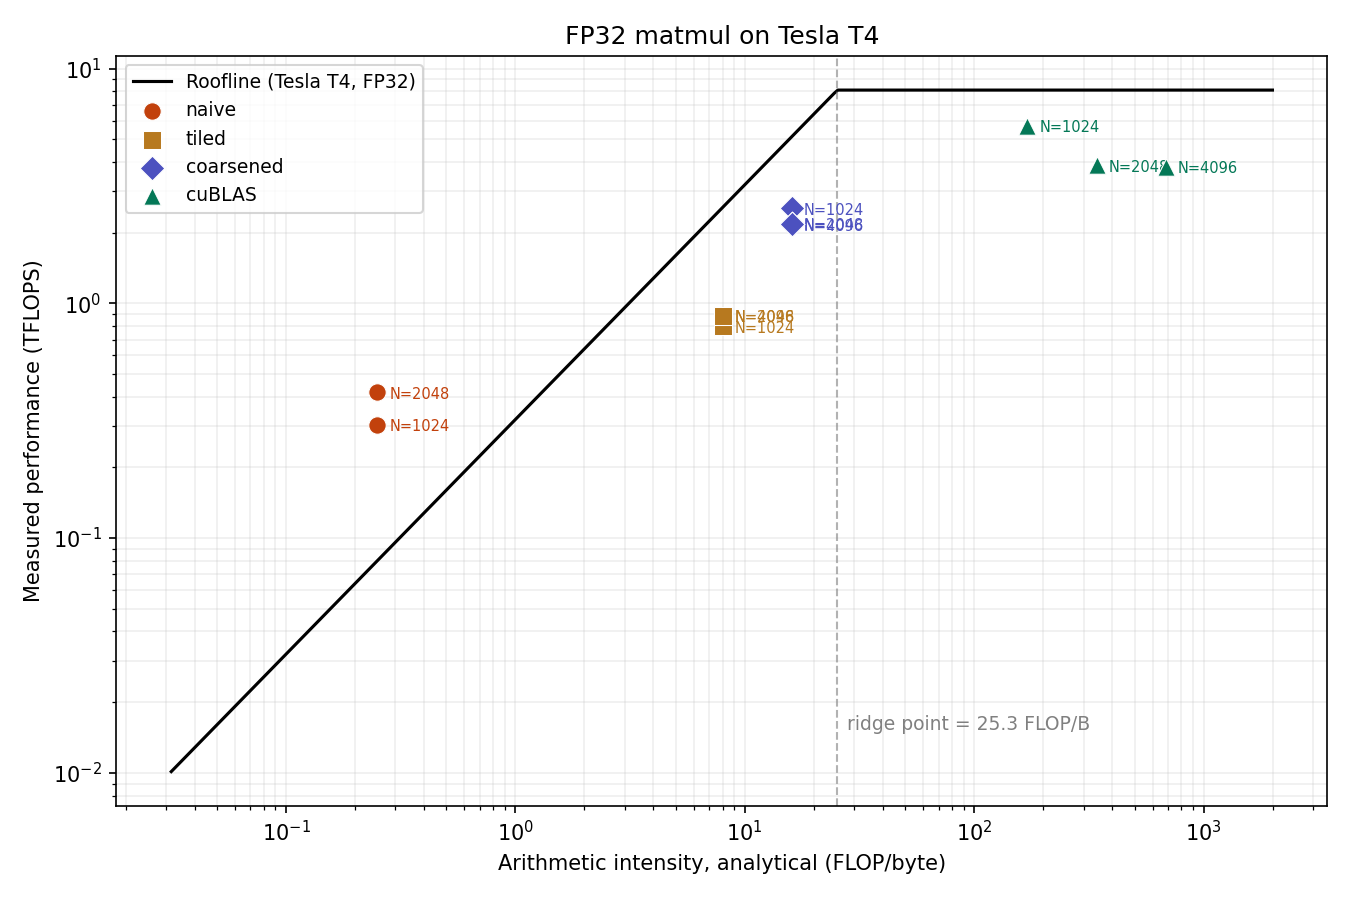

| kernel    |    N |   time_ms |   tflops |      ai |   pct_of_peak |   pct_of_cublas |
|:----------|-----:|----------:|---------:|--------:|--------------:|----------------:|
| naive     |  256 |     0.128 |    0.262 |   0.250 |         3.240 |          32.109 |
| tiled     |  256 |     0.086 |    0.389 |   8.000 |         4.800 |          47.578 |
| coarsened |  256 |     0.052 |    0.640 |  16.000 |         7.898 |          78.275 |
| cuBLAS    |  256 |     0.041 |    0.817 |  42.667 |        10.090 |         100.000 |
| naive     |  512 |     0.921 |    0.292 |   0.250 |         3.600 |          12.045 |
| tiled     |  512 |     0.590 |    0.455 |   8.000 |         5.618 |          18.797 |
| coarsened |  512 |     0.339 |    0.793 |  16.000 |         9.787 |          32.746 |
| cuBLAS    |  512 |     0.111 |    2.421 |  85.333 |        29.886 |         100.000 |
| naive     | 1024 |     7.272 |    0.295 |   0.250 |         3.646 |           5.234 |
| tiled     | 1024 |     2.398 |    0.896 |   8.000 |        11.056 |          15.873 |
| coarsened | 1024 |     1.193 |    1.800 |  16.000 |        22.219 |          31.899 |
| cuBLAS    | 1024 |     0.381 |    5.642 | 170.667 |        69.655 |         100.000 |
| naive     | 2048 |    41.781 |    0.411 |   0.250 |         5.076 |          10.598 |
| tiled     | 2048 |    19.764 |    0.869 |   8.000 |        10.732 |          22.404 |
| coarsened | 2048 |     9.919 |    1.732 |  16.000 |        21.383 |          44.641 |
| cuBLAS    | 2048 |     4.428 |    3.880 | 341.333 |        47.899 |         100.000 |
| tiled     | 4096 |   159.775 |    0.860 |   8.000 |        10.620 |          23.039 |
| coarsened | 4096 |    82.026 |    1.676 |  16.000 |        20.686 |          44.878 |
| cuBLAS    | 4096 |    36.811 |    3.734 | 682.667 |        46.094 |         100.000 |

| kernel    |    N |   time_ms |   tflops |      ai |   pct_of_peak |   pct_of_cublas |
|:----------|-----:|----------:|---------:|--------:|--------------:|----------------:|
| naive     | 1024 |     7.057 |    0.304 |   0.250 |         3.757 |           5.327 |
| tiled     | 1024 |     2.691 |    0.798 |   8.000 |         9.851 |          13.966 |
| coarsened | 1024 |     0.846 |    2.539 |  16.000 |        31.345 |          44.440 |
| cuBLAS    | 1024 |     0.376 |    5.713 | 170.667 |        70.535 |         100.000 |
| naive     | 2048 |    41.195 |    0.417 |   0.250 |         5.149 |          10.772 |
| tiled     | 2048 |    19.420 |    0.885 |   8.000 |        10.921 |          22.849 |
| coarsened | 2048 |     7.867 |    2.184 |  16.000 |        26.960 |          56.405 |
| cuBLAS    | 2048 |     4.437 |    3.872 | 341.333 |        47.797 |         100.000 |
| tiled     | 4096 |   155.878 |    0.882 |   8.000 |        10.885 |          23.159 |
| coarsened | 4096 |    63.419 |    2.167 |  16.000 |        26.755 |          56.923 |
| cuBLAS    | 4096 |    36.100 |    3.807 | 682.667 |        47.002 |         100.000 |

In [9]:
from IPython.display import Image, Markdown, display
import glob
for png in sorted(glob.glob('results/roofline_*.png')):
    display(Image(png))
for md in sorted(glob.glob('results/results_*.md')):
    display(Markdown(open(md).read()))

In [10]:
!zip -qr results.zip results
from google.colab import files
files.download('results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
!pip install ninja